# Notebook 04 - Contours and bounding boxes

*Time: about 50-60 minutes*

## What you will learn
- A **contour** is the outline of a white shape. OpenCV can find all of them for us.
- How to draw contours and **bounding boxes** `(x, y, w, h)`.
- How to measure a shape's **area** and use it to **filter out specks**.
- How to **crop** every box into its own small picture.
- How to **sort** boxes from left to right (and top to bottom).

## Prerequisites
- Notebook 03: we start from the cleaning recipe (gray, median blur, Otsu, flip to white-on-black).

### What this code does

We load the libraries. Only OpenCV and our helpers are needed this time.

In [1]:
import sys                                    # lets us change where Python looks for files
sys.path.append("..")                         # also look one folder up (utils.py lives there)
import cv2                                    # OpenCV
from utils import load, show_many             # our helpers
print("Libraries loaded - ready to go!")      # a visible sign that everything worked

Libraries loaded - ready to go!


### What you should see / Why we care

`Libraries loaded - ready to go!`

### What this code does

We load the noisy letters and run the **cleaning recipe from Notebook 03**. The result `thresh` is the picture the contour finder needs: **white shapes on a black background**.

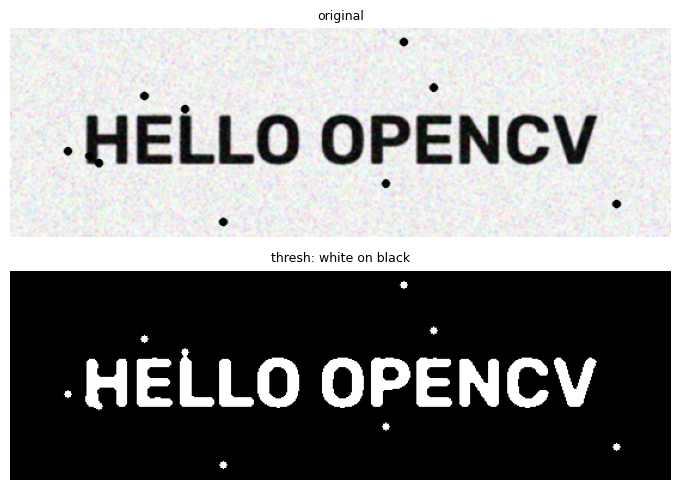

In [2]:
IMAGE_PATH = "../assets/letters_noisy.png"    # <- change this line to use another picture
img = load(IMAGE_PATH)                        # colour picture (for drawing on later)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # 1. gray
blur = cv2.medianBlur(gray, 5)                # 2. remove noise
_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)  # 3. black/white
thresh = cv2.bitwise_not(thresh)              # 4. white text on black
show_many([img, thresh], ["original", "thresh: white on black"], columns=1, size=(8, 5))

### What you should see / Why we care

The top picture is the noisy original, the bottom one is clean white letters on black with a few **white dots** (the dust specks). Those dots will become "objects" too, and we will remove them in a minute.

### What this code does

`cv2.findContours` walks around the edge of every white shape.
- `cv2.RETR_EXTERNAL` = "only the **outer** outline of each shape" (we ignore the holes inside letters such as O).
- `cv2.CHAIN_APPROX_SIMPLE` = "store only the corner points, not every pixel" (saves memory).

It gives back a list of contours. `len(contours)` is how many shapes it found.

In [3]:
contours, hierarchy = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print("number of contours found:", len(contours))     # how many white shapes?
print("first contour has", len(contours[0]), "corner points")  # a contour = list of points

number of contours found: 18
first contour has 16 corner points


### What you should see / Why we care

You should see that **more contours than letters** were found (the text has 11 letters, the rest are dust specks).

*Version note:* OpenCV 4 returns **2** values (`contours, hierarchy`). Old OpenCV 3 returned 3. The README troubleshooting section explains this.

### What this code does

`cv2.drawContours(picture, contours, -1, colour, thickness)` draws outlines. The `-1` means "draw all of them". We draw on a **copy** (`img.copy()`) so the original stays untouched.

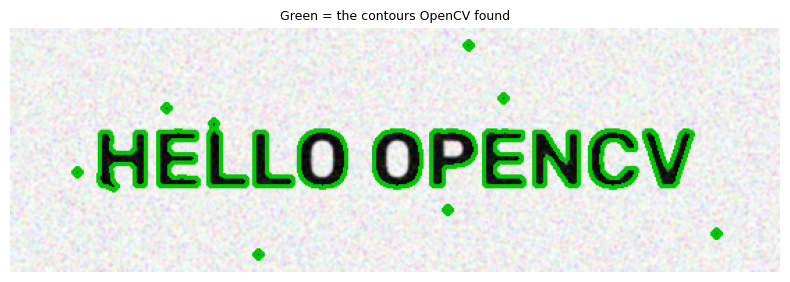

In [4]:
outlined = img.copy()                                   # copy so we keep the original
cv2.drawContours(outlined, contours, -1, (0, 200, 0), 2)  # green outlines, 2 pixels thick
show_many([outlined], ["Green = the contours OpenCV found"], columns=1, size=(8, 3))

### What you should see / Why we care

A **green outline** around every letter and also around every speck.

### What this code does

A **bounding box** is the smallest upright rectangle that surrounds a contour. `cv2.boundingRect(contour)` returns four numbers: `x, y` (top-left corner), `w, h` (width and height). We loop over all contours and draw each box with `cv2.rectangle`.

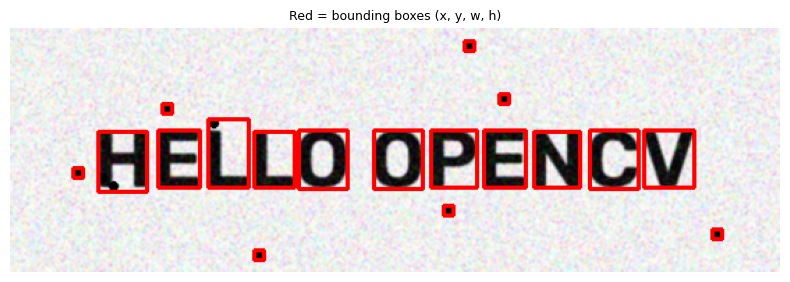

In [5]:
boxed = img.copy()                                      # fresh copy
for contour in contours:                                # one contour at a time
    x, y, w, h = cv2.boundingRect(contour)              # the four numbers of its box
    cv2.rectangle(boxed, (x, y), (x + w, y + h), (0, 0, 255), 2)  # red rectangle
show_many([boxed], ["Red = bounding boxes (x, y, w, h)"], columns=1, size=(8, 3))

### What you should see / Why we care

A **red rectangle** around each shape. `(x, y)` is the top-left corner and `(x + w, y + h)` is the bottom-right corner.

## Measuring shapes

`cv2.contourArea(contour)` returns the area (in pixels) inside a contour. Letters have big areas. Specks have tiny ones. That difference is how we filter.

### What this code does

We print `x, y, w, h` and the area for the first 6 contours. The odd-looking `"{:>4}"` pieces are just a way to line the numbers up in neat columns (`>4` means "right-aligned in 4 characters").

In [6]:
print("  #    x    y    w    h    area")                # column titles
for index in range(6):                                  # the first 6 contours
    x, y, w, h = cv2.boundingRect(contours[index])      # its box
    area = cv2.contourArea(contours[index])             # its area
    print("{:>3} {:>4} {:>4} {:>4} {:>4} {:>7.0f}".format(index, x, y, w, h, area))

  #    x    y    w    h    area
  0  175  159    7    7      20
  1  504  144    7    7      20
  2  311  127    7    7      20
  3   45  100    7    7      20
  4  376   74   33   40     840
  5  175   74   29   40     478


### What you should see / Why we care

A little table. Notice that the **order is not left-to-right**: OpenCV returns contours in whatever order it found them. Also compare areas: letters are in the **hundreds** (478 and up), specks are only about **20**.

### What this code does

Let us look at **all** the areas at once. We make an empty list, add every area to it (`append`), then sort it from small to big.

In [7]:
areas = []                                              # an empty list
for contour in contours:                                # visit every contour
    areas.append(int(cv2.contourArea(contour)))         # add its area (as a whole number)
areas.sort()                                            # smallest first
print("all areas, smallest to biggest:")                # headline
print(areas)                                            # the whole list

all areas, smallest to biggest:
[20, 20, 20, 20, 20, 20, 20, 478, 509, 631, 668, 684, 703, 806, 840, 857, 1175, 1177]


### What you should see / Why we care

A list that starts with small numbers (`20, 20, 20 ...` the specks) and then **jumps** to `478` and more (the letters). That jump is the gap where we can draw the line.

### What this code does

**Area filter.** We choose a minimum area (`MIN_AREA = 60`) and keep only the contours at least that big. We build a new list `good` with a loop and an `if`.

In [8]:
MIN_AREA = 60                                           # smaller than this = dust
good = []                                               # contours we keep
for contour in contours:                                # check every contour
    if cv2.contourArea(contour) >= MIN_AREA:            # big enough?
        good.append(contour)                            # yes: keep it
print("before filter:", len(contours), "contours")      # count before
print("after filter :", len(good), "contours")          # count after

before filter: 18 contours
after filter : 11 contours


### What you should see / Why we care

The count **goes down** to `11`, exactly the number of letters in "HELLO OPENCV" (the space is not a letter).

### What this code does

We draw the boxes **before** (red, all contours) and **after** (green, filtered) the area filter, to see which shapes disappeared.

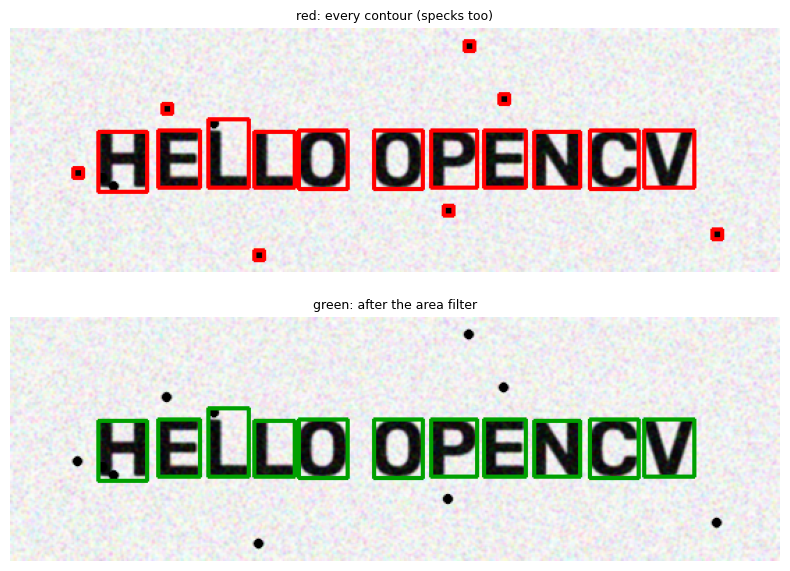

In [9]:
before = img.copy()                                     # picture for "before"
after = img.copy()                                      # picture for "after"
for contour in contours:                                # all contours: red boxes
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(before, (x, y), (x + w, y + h), (0, 0, 255), 2)
for contour in good:                                    # only good ones: green boxes
    x, y, w, h = cv2.boundingRect(contour)
    cv2.rectangle(after, (x, y), (x + w, y + h), (0, 160, 0), 2)
show_many([before, after], ["red: every contour (specks too)", "green: after the area filter"], columns=1, size=(8, 6))

### What you should see / Why we care

The top picture has extra red boxes around specks. In the bottom picture **only the letters** are boxed.

## Sorting and cropping

To read text we need the letters **in order, left to right**. A *box* is a tuple `(x, y, w, h)`. Python can sort tuples: it compares the **first number** (`x`) first. So a plain `sorted(boxes)` already sorts by `x`, which means left to right!

### What this code does

We store each good contour's box in a list called `boxes`, then print the first four `x` values. Because OpenCV does not return contours in reading order, the `x` values will look mixed up (often right to left).

In [10]:
boxes = []                                              # an empty list of boxes
for contour in good:                                    # every good contour
    boxes.append(cv2.boundingRect(contour))             # store (x, y, w, h)
x_values = []                                           # just the x of each box
for box in boxes:
    x_values.append(box[0])                             # box[0] is x
print("x values in OpenCV's order:", x_values[:4], "...")  # first four only

x values in OpenCV's order: [376, 175, 63, 455] ...


### What you should see / Why we care

The `x` values are **not increasing**, so the letters would be read in the wrong order.

### What this code does

`sorted(boxes)` returns a new list in order of `x`. We print the x values again to check.

In [11]:
boxes = sorted(boxes)                                   # sort by x (then y): left to right
x_values = []                                           # rebuild the x list
for box in boxes:
    x_values.append(box[0])                             # box[0] is x
print("x values after sorting:", x_values)              # should now only increase

x values after sorting: [63, 106, 142, 175, 207, 261, 302, 340, 376, 416, 455]


### What you should see / Why we care

The `x` values now **increase from left to right**: 11 numbers, from the `H` to the `V`.

### What this code does

**Cropping.** For every box we cut the same rectangle out of `thresh` using slicing (remember `picture[rows, columns]`, so it is `[y : y + h, x : x + w]`). We collect the crops and give each a title "box 0, box 1, ...".

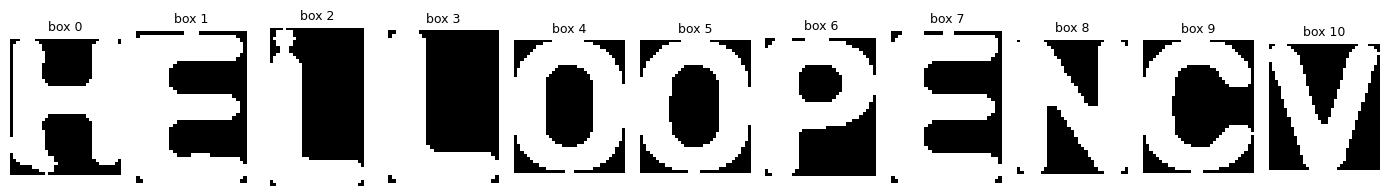

In [12]:
crops = []                                              # the small pictures
titles = []                                             # their titles
for index in range(len(boxes)):                         # box number 0, 1, 2, ...
    x, y, w, h = boxes[index]                           # unpack the box
    crops.append(thresh[y:y + h, x:x + w])              # cut it out
    titles.append("box " + str(index))                  # "box 0", "box 1", ...
show_many(crops, titles, columns=11, size=(14, 2))      # one row of thumbnails

### What you should see / Why we care

Eleven small pictures in a row: **H, E, L, L, O, O, P, E, N, C, V**, each in its own box. We have **segmented** the text into single characters. That is the key step before recognition.

### What this code does

**Top to bottom.** For pictures with several lines of text we sort by `y` instead. `sorted(..., key=get_y)` means "sort, but compare the number that `get_y` gives me". `get_y` is a tiny **function** (a named recipe): it receives a box and hands back its second number.

In [13]:
def get_y(box):                                         # a recipe named get_y
    return box[1]                                       # give back y (second number)
demo_boxes = [(300, 20, 10, 10), (20, 200, 10, 10), (150, 45, 10, 10)]  # made-up boxes
print("sorted by x (left to right):", sorted(demo_boxes))
print("sorted by y (top to bottom):", sorted(demo_boxes, key=get_y))

sorted by x (left to right): [(20, 200, 10, 10), (150, 45, 10, 10), (300, 20, 10, 10)]
sorted by y (top to bottom): [(300, 20, 10, 10), (150, 45, 10, 10), (20, 200, 10, 10)]


### What you should see / Why we care

The first line starts with the box at `x = 20` (the leftmost); the second starts with `y = 20` (the highest, i.e. smallest `y`). Same boxes, different order. In Notebook 08 we combine both: first group boxes into **rows** by `y`, then sort each row by `x`.

## Recap
| Idea | Code |
|---|---|
| Find outlines | `contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)` |
| Box of a contour | `x, y, w, h = cv2.boundingRect(contour)` |
| Size of a contour | `cv2.contourArea(contour)` |
| Remove specks | keep only `area >= MIN_AREA` |
| Reading order | `sorted(boxes)` |
| Cut out | `thresh[y:y + h, x:x + w]` |

**Next:** Notebook 05 teaches the computer to recognise each letter.